# Demostracion del analisis internacional
Este notebook presenta los resultados aprobados de la fase `03_analisis_datos` sin volver a procesar el Parquet ni ejecutar consultas pesadas sobre MySQL. Lee exclusivamente artefactos ya calculados.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS = PROJECT_ROOT / 'data' / '03_analysis_output'
eda = json.loads((RESULTS / 'eda' / 'perfil_global.json').read_text(encoding='utf-8'))
quality = json.loads((RESULTS / 'calidad_cobertura' / 'calidad_global.json').read_text(encoding='utf-8'))
sql_state = json.loads((RESULTS / 'validacion_sql' / 'estado.json').read_text(encoding='utf-8'))
coverage = pd.read_csv(RESULTS / 'calidad_cobertura' / 'cobertura_por_fuente.csv')
ranges = pd.read_csv(RESULTS / 'calidad_cobertura' / 'controles_de_rango.csv')
temporal = pd.read_csv(RESULTS / 'analisis_temporal' / 'cobertura_diaria.csv')
comparison = pd.read_csv(RESULTS / 'comparacion_fuentes' / 'matriz_comparabilidad.csv')
tsi = pd.read_csv(RESULTS / 'indicador_tsi' / 'tsi_provisional_diario.csv')
print('Artefactos cargados sin reprocesar el dataset.')

Artefactos cargados sin reprocesar el dataset.


In [2]:
kpis = pd.DataFrame([
    {'indicador': 'observaciones_parquet', 'valor': eda['filas']},
    {'indicador': 'grupos_ciudad_fuente_metrica', 'valor': eda['grupos_ciudad_fuente_metrica']},
    {'indicador': 'fuentes', 'valor': coverage['fuente'].nunique()},
    {'indicador': 'controles_rango_invalidos', 'valor': sum(quality['controles_de_rango'].values())},
    {'indicador': 'observaciones_mysql', 'valor': sql_state['observaciones_mysql']},
    {'indicador': 'diferencia_parquet_mysql', 'valor': sql_state['diferencia_total']},
    {'indicador': 'dias_fuente_tsi', 'valor': tsi['fecha'].nunique()},
])
display(kpis)

,indicador,valor
0,observaciones_parquet,41770880
1,grupos_ciudad_fuente_metrica,5
2,fuentes,5
3,controles_rango_invalidos,0
4,observaciones_mysql,41770880
5,diferencia_parquet_mysql,0
6,dias_fuente_tsi,8320


In [3]:
source_summary = coverage.groupby('fuente', as_index=False).agg(
    observaciones=('observaciones', 'sum'),
    fecha_minima=('timestamp_minimo', 'min'),
    fecha_maxima=('timestamp_maximo', 'max'),
    nulos_valor_principal=('nulos_valor_principal', 'sum'),
)
source_summary['dias_observados'] = temporal.groupby('fuente')['fecha'].nunique().reindex(source_summary['fuente']).to_numpy()
source_summary['tsi_medio'] = tsi.groupby('fuente')['tsi_provisional_media'].mean().reindex(source_summary['fuente']).to_numpy()
display(source_summary.sort_values('observaciones', ascending=False))

,fuente,observaciones,fecha_minima,fecha_maxima,nulos_valor_principal,dias_observados,tsi_medio
3,pems_bay,16937700,2017-01-01T00:00:00,2017-06-30T23:55:00,0,181,73.584399
1,madrid_traffic_points,12512133,2022-12-01T00:00:00,2022-12-31T23:45:00,0,31,98.609834
2,metr_la,7094304,2012-03-01T00:00:00,2012-06-27T23:55:00,0,119,76.741459
4,sao_paulo_cet,5223411,2001-01-02T07:30:00,2018-09-30T19:30:00,0,6094,94.243199
0,istanbul_traffic_index,3332,2015-08-06T00:00:00,2024-10-18T00:00:00,0,3332,54.157017


In [4]:
display(ranges)
display(comparison[['fuente', 'metrica_principal', 'familia_metrica', 'unidad_conceptual', 'comparacion_directa']])
sql_table = pd.DataFrame([sql_state])
display(sql_table[['estado', 'observaciones_parquet', 'observaciones_mysql', 'diferencia_total']])

,control,registros_invalidos
0,latitud_fuera_rango,0
1,longitud_fuera_rango,0
2,periodo_no_positivo,0
3,timestamp_invalido,0
4,valor_fuente_negativo,0
5,valor_principal_negativo,0


,fuente,metrica_principal,familia_metrica,unidad_conceptual,comparacion_directa
0,sao_paulo_cet,congestion_longitud_m,congestion_longitud,longitud congestionada,False
1,istanbul_traffic_index,indice_congestion,indice_congestion,indice relativo,False
2,madrid_traffic_points,intensidad,intensidad,intensidad de trafico,False
3,metr_la,velocidad_sensor,velocidad,velocidad de sensor,True
4,pems_bay,velocidad_sensor,velocidad,velocidad de sensor,True


,estado,observaciones_parquet,observaciones_mysql,diferencia_total
0,completa,41770880,41770880,0


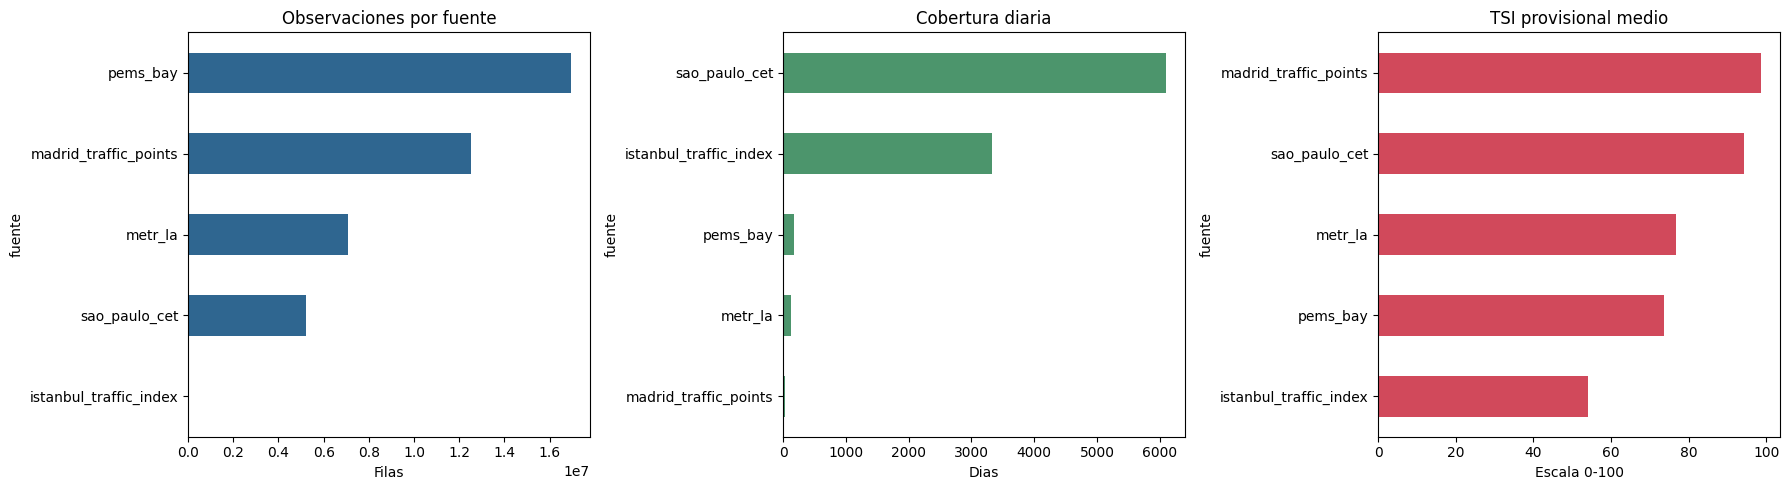

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
source_summary.sort_values('observaciones').plot.barh(x='fuente', y='observaciones', ax=axes[0], legend=False, color='#2f6690')
axes[0].set_title('Observaciones por fuente')
axes[0].set_xlabel('Filas')
source_summary.sort_values('dias_observados').plot.barh(x='fuente', y='dias_observados', ax=axes[1], legend=False, color='#4c956c')
axes[1].set_title('Cobertura diaria')
axes[1].set_xlabel('Dias')
source_summary.sort_values('tsi_medio').plot.barh(x='fuente', y='tsi_medio', ax=axes[2], legend=False, color='#d1495b')
axes[2].set_title('TSI provisional medio')
axes[2].set_xlabel('Escala 0-100')
plt.tight_layout()
plt.show()

## Conclusiones demostradas
- El consolidado contiene 41,770,880 observaciones y cinco grupos ciudad-fuente-metrica.
- Los controles de rango no reportan registros invalidos.
- Las fuentes no se comparan en escala original cuando sus metricas tienen distinta unidad.
- El TSI mostrado es provisional y se conserva separado por fuente.
- La validacion SQL coincide por conteo total y fuente.

Este notebook es una demostracion rapida: no reemplaza los notebooks metodologicos ni vuelve a ejecutar sus pipelines.